# Notebook 03 — Material Classification using Random Forest

## Objective

In this experiment, we will train a machine-learning model to predict a broad material group from recorded product properties.

This is a **supervised-learning** task: the dataset already contains material-group labels, and the model learns patterns from records where those labels are known.

For this first experiment, we will predict the broad material category group rather than the more detailed material family. The broad groups have more records, which gives us a more suitable starting point for classification.

**Important:** A prediction is an indication based on the information available to the model. It is not a verified product classification and must not replace manufacturer documentation.

## 1. Environment and project path

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib

warnings.filterwarnings("ignore", category=FutureWarning)

DATASET_RELATIVE = Path(
    "04_Product_Dataset",
    "10_Master_Database",
    "SpecSynth_Master_Database_v1.0",
    "source_data",
    "v1.5.0"
)

def find_project_root(start):
    start = start.resolve()
    for candidate in [start, *start.parents]:
        dataset_file = (
            candidate / DATASET_RELATIVE / "ml" /
            "SpecSynth_ML_variants_v1.5.0.csv"
        )
        if dataset_file.exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the SpecSynth project root. "
        "Open this notebook from inside the SpecSynth_AI project."
    )

PROJECT_ROOT = find_project_root(Path.cwd())
ML_ROOT = PROJECT_ROOT / "06_AI_Performance_Engine" / "02_ML_Engine"
DATA_DIR = PROJECT_ROOT / DATASET_RELATIVE / "ml"

MODEL_DIR = ML_ROOT / "03_Models" / "material_classification"
REPORT_DIR = ML_ROOT / "04_Evaluation" / "reports"
FIGURE_DIR = ML_ROOT / "04_Evaluation" / "figures"

for folder in [MODEL_DIR, REPORT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

CSV_PATH = DATA_DIR / "SpecSynth_ML_variants_v1.5.0.csv"

print("Project root:", PROJECT_ROOT)
print("Dataset:", CSV_PATH)

Project root: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI
Dataset: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\04_Product_Dataset\10_Master_Database\SpecSynth_Master_Database_v1.0\source_data\v1.5.0\ml\SpecSynth_ML_variants_v1.5.0.csv


### Outcome and conclusion

The notebook has located the SpecSynth product dataset and prepared separate folders for the trained classifier and its evaluation reports. The original dataset will only be read and will not be modified.

## 2. Load dataset and identify the classification label

In [2]:
df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)

# Find the broad material-group label.
target_candidates = [
    "material_category_group",
    "material_group",
    "category_group",
    "material_category"
]
TARGET = next((c for c in target_candidates if c in df.columns), None)

if TARGET is None:
    raise KeyError(
        "Could not find a broad material-group label. "
        f"Checked: {target_candidates}. "
        "Inspect df.columns and update TARGET to the correct broad-group column."
    )

print("Classification target:", TARGET)
print("\\nTarget class counts:")
display(df[TARGET].value_counts(dropna=False).rename("records").to_frame())

print("\\nAvailable split counts:")
display(df["recommended_split"].value_counts(dropna=False).rename("records").to_frame())

Dataset shape: (1941, 47)
Classification target: material_category_group
\nTarget class counts:


,records
material_category_group,
A_thermal_insulation,1674
F_envelope,79
G_glazing,66
E_boards,52
D_timber_biobased,35
B_masonry,24
C_concrete,11


\nAvailable split counts:


,records
recommended_split,
train,1621
validation,186
test,134


### Outcome and conclusion

The prediction target is `material_category_group`, with seven groups. The dataset is strongly imbalanced: thermal insulation contains **1,674 of 1,941 records (86.2%)**, while concrete has only **11 records** and masonry has **24**.

This imbalance matters. A model can achieve high overall accuracy by predicting the dominant group, while performing poorly on smaller groups. That is why we compare balanced accuracy and macro F1 in addition to ordinary accuracy.

The original split contains 1,621 training, 186 validation and 134 test records. We preserve it rather than creating a new random split.

## 3. Prepare labels and preserve the existing data split

In [3]:
# Define candidate numerical properties before building the working table.
# This list is repeated in the feature-selection section for readability.
candidate_features = [
    "thickness_mm",
    "thermal_conductivity_W_mK",
    "thermal_resistance_m2K_W",
    "density_kg_m3",
    "specific_heat_J_kgK",
    "vapour_resistance_factor_mu",
    "compressive_strength_kPa",
    "tensile_strength_perpendicular_kPa",
    "mass_per_area_kg_m2",
    "Ug_W_m2K"
]

# Keep identifiers/labels for tracking, plus the candidate numeric input features.
# The previous version retained only metadata columns, which caused the feature
# preparation cell to fail with a KeyError.
metadata_columns = [
    c for c in ["record_id", "variant_id", "product_id", "material_family", TARGET, "recommended_split"]
    if c in df.columns
]
feature_source_columns = [
    c for c in candidate_features if c in df.columns
]
work_columns = list(dict.fromkeys(metadata_columns + feature_source_columns))

work = df[work_columns].copy()
work[TARGET] = work[TARGET].astype("string").str.strip()

valid_label = work[TARGET].notna() & work[TARGET].ne("")
valid_split = work["recommended_split"].notna()

work = work.loc[valid_label & valid_split].copy()
work["recommended_split"] = work["recommended_split"].astype(str).str.lower()

train_df = work[work["recommended_split"] == "train"].copy()
val_df = work[work["recommended_split"].isin(["validation", "val"])].copy()
test_df = work[work["recommended_split"] == "test"].copy()

print("Records with valid label and split:", len(work))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\\nClasses in training:", train_df[TARGET].nunique())
print("Classes in validation:", val_df[TARGET].nunique())
print("Classes in testing:", test_df[TARGET].nunique())

train_classes = set(train_df[TARGET].unique())
val_only = sorted(set(val_df[TARGET].unique()) - train_classes)
test_only = sorted(set(test_df[TARGET].unique()) - train_classes)

print("\\nValidation classes not present in training:", val_only)
print("Test classes not present in training:", test_only)

Records with valid label and split: 1941
Training: 1621
Validation: 186
Testing: 134
\nClasses in training: 7
Classes in validation: 5
Classes in testing: 6
\nValidation classes not present in training: []
Test classes not present in training: []


### Implementation note

The working table retains both the record metadata and the candidate numerical properties. The metadata is used to preserve labels and the original split; the numerical properties become the model inputs. This is necessary because the model cannot train from identifiers and labels alone.

### Outcome and conclusion

All **1,941 records** have a valid target label and split assignment. The original split is preserved: 1,621 train, 186 validation and 134 test records.

All seven material groups occur in training. Five occur in validation and six occur in testing. No validation or test class is entirely absent from training, so the model has examples of every evaluated class available during training.

Preserving the existing split also preserves the dataset's group-based separation rules.

## 4. Select input features

In [4]:
# Candidate numerical properties. IDs, labels, product names and split fields are excluded.
candidate_features = [
    "thickness_mm",
    "thermal_conductivity_W_mK",
    "thermal_resistance_m2K_W",
    "density_kg_m3",
    "specific_heat_J_kgK",
    "vapour_resistance_factor_mu",
    "compressive_strength_kPa",
    "tensile_strength_perpendicular_kPa",
    "mass_per_area_kg_m2",
    "Ug_W_m2K"
]

available_features = [c for c in candidate_features if c in df.columns]

coverage = pd.DataFrame({
    "feature": available_features,
    "available_records": [df[c].notna().sum() for c in available_features],
    "coverage_percent": [df[c].notna().mean() * 100 for c in available_features]
}).sort_values("coverage_percent", ascending=False)

display(coverage)

# Keep properties available in at least 20% of the complete dataset.
numeric_features = coverage.loc[
    coverage["coverage_percent"] >= 20, "feature"
].tolist()

if len(numeric_features) < 2:
    raise ValueError(
        "Fewer than two numerical features meet the coverage threshold. "
        "Review the coverage table and adjust the feature-selection rule."
    )

print("Selected numerical features:", numeric_features)

,feature,available_records,coverage_percent
0,thickness_mm,1926,99.227202
2,thermal_resistance_m2K_W,1820,93.766100
1,thermal_conductivity_W_mK,1781,91.756826
6,compressive_strength_kPa,668,34.415250
5,vapour_resistance_factor_mu,624,32.148377
7,tensile_strength_perpendicular_kPa,620,31.942298
3,density_kg_m3,292,15.043792
8,mass_per_area_kg_m2,280,14.425554
4,specific_heat_J_kgK,122,6.285420
9,Ug_W_m2K,66,3.400309


Selected numerical features: ['thickness_mm', 'thermal_resistance_m2K_W', 'thermal_conductivity_W_mK', 'compressive_strength_kPa', 'vapour_resistance_factor_mu', 'tensile_strength_perpendicular_kPa']


### Outcome and conclusion

Six numerical properties were selected because they meet the notebook's 20% coverage threshold:

- Thickness: 99.2% coverage.
- Thermal resistance: 93.8%.
- Thermal conductivity: 91.8%.
- Compressive strength: 34.4%.
- Vapour resistance factor: 32.1%.
- Tensile strength perpendicular: 31.9%.

Density, mass per area, specific heat and Ug were excluded because their coverage was too low under this rule.

The selected inputs are physical and thermal properties, not product IDs, manufacturer names or material-family labels. This reduces the risk of the model simply memorising product identity or being given the answer directly.

## 5. Prepare the feature matrix

In [5]:
X_train = train_df[numeric_features].apply(pd.to_numeric, errors="coerce")
X_val = val_df[numeric_features].apply(pd.to_numeric, errors="coerce")
X_test = test_df[numeric_features].apply(pd.to_numeric, errors="coerce")

y_train = train_df[TARGET].astype(str)
y_val = val_df[TARGET].astype(str)
y_test = test_df[TARGET].astype(str)

# Remove features that are entirely missing in the training split.
usable_features = [
    c for c in numeric_features
    if X_train[c].notna().any()
]

X_train = X_train[usable_features]
X_val = X_val[usable_features]
X_test = X_test[usable_features]

if not usable_features:
    raise ValueError("No selected feature has any training values.")

print("Final features:", usable_features)
print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)
print("Testing matrix:", X_test.shape)
print("Missing training feature values:", int(X_train.isna().sum().sum()))

Final features: ['thickness_mm', 'thermal_resistance_m2K_W', 'thermal_conductivity_W_mK', 'compressive_strength_kPa', 'vapour_resistance_factor_mu', 'tensile_strength_perpendicular_kPa']
Training matrix: (1621, 6)
Validation matrix: (186, 6)
Testing matrix: (134, 6)
Missing training feature values: 3493


### Outcome and conclusion

The training matrix contains **1,621 records and six features**. The validation matrix contains 186 records and the test matrix contains 134 records.

There are **3,493 missing feature values** in the training matrix. The models use median imputation inside their preprocessing pipelines. Each model therefore learns imputation values from training data only, then applies those values to validation and test data.

This is important because missing properties are common in the product dataset. Predictions should be interpreted with awareness that some records have fewer measured properties than others.

## 6. Define multiple classification models

We will compare several algorithms rather than assuming that Random Forest is the best choice.

The comparison includes:
- **Dummy Classifier:** a simple baseline that predicts the most common class. Other models should do better than this.
- **Logistic Regression:** a simple statistical classification model.
- **Decision Tree:** learns a set of decision rules.
- **Random Forest:** combines many decision trees.
- **Extra Trees:** combines highly randomised decision trees.
- **Gradient Boosting:** builds trees sequentially, with each new tree trying to improve on earlier errors.

All models use the same training records and the same input features. Preprocessing is placed inside each pipeline so that missing-value handling and scaling are learned from training data only.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

def make_preprocessor(scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    return Pipeline(steps=steps)

models = {
    "Dummy Baseline": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]),
    "Logistic Regression": Pipeline([
        ("preprocessor", make_preprocessor(scale=True)),
        ("classifier", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        ))
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", DecisionTreeClassifier(
            max_depth=None,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=42
        ))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=400,
            random_state=42,
            class_weight="balanced_subsample",
            min_samples_leaf=2,
            n_jobs=-1
        ))
    ]),
    "Extra Trees": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", ExtraTreesClassifier(
            n_estimators=400,
            random_state=42,
            class_weight="balanced",
            min_samples_leaf=2,
            n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=2,
            random_state=42
        ))
    ])
}

print("Models to compare:")
for name in models:
    print("-", name)

Models to compare:
- Dummy Baseline
- Logistic Regression
- Decision Tree
- Random Forest
- Extra Trees
- Gradient Boosting


### Outcome and conclusion

Six algorithms are compared: a Dummy baseline, Logistic Regression, Decision Tree, Random Forest, Extra Trees and Gradient Boosting.

The Dummy baseline is essential because it shows the result of always predicting the most common class. The comparison uses the same training and validation records for every model.

Macro F1 is the primary selection metric because it gives each material group equal importance, rather than allowing the very large insulation group to dominate the score.

## 7. Train models and compare validation results

In [7]:
comparison_rows = []
fitted_models = {}

for name, candidate in models.items():
    print(f"Training: {name}")
    candidate.fit(X_train, y_train)
    fitted_models[name] = candidate

    pred = candidate.predict(X_val)

    comparison_rows.append({
        "model": name,
        "validation_accuracy": accuracy_score(y_val, pred),
        "validation_balanced_accuracy": balanced_accuracy_score(y_val, pred),
        "validation_macro_f1": f1_score(
            y_val, pred, average="macro", zero_division=0
        )
    })

comparison = pd.DataFrame(comparison_rows).sort_values(
    ["validation_macro_f1", "validation_balanced_accuracy"],
    ascending=False
).reset_index(drop=True)

display(comparison.round(4))

Training: Dummy Baseline
Training: Logistic Regression
Training: Decision Tree
Training: Random Forest


c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Training: Extra Trees
Training: Gradient Boosting


c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,model,validation_accuracy,validation_balanced_accuracy,validation_macro_f1
0,Extra Trees,1.0000,1.0000,1.0000
1,Random Forest,0.9892,0.9976,0.8323
2,Decision Tree,0.9785,0.9952,0.8313
3,Gradient Boosting,0.9785,0.9952,0.8313
4,Logistic Regression,0.5645,0.8048,0.5725
5,Dummy Baseline,0.9032,0.2000,0.1898


### Outcome and conclusion — actual validation results

The validation comparison produced these results:

| Model | Accuracy | Balanced accuracy | Macro F1 |
|---|---:|---:|---:|
| Extra Trees | **1.0000** | **1.0000** | **1.0000** |
| Random Forest | 0.9892 | 0.9976 | 0.8323 |
| Decision Tree | 0.9785 | 0.9952 | 0.8313 |
| Gradient Boosting | 0.9785 | 0.9952 | 0.8313 |
| Logistic Regression | 0.5645 | 0.8048 | 0.5725 |
| Dummy Baseline | 0.9032 | 0.2000 | 0.1898 |

Extra Trees achieved a perfect score on this validation set. Random Forest was the next strongest model, with a macro F1 of 0.8323.

The Dummy baseline illustrates why accuracy alone is misleading: it reached 90.32% accuracy but only 0.1898 macro F1. It mostly benefits from the dominant insulation category.

The perfect Extra Trees validation score is unusually strong. It must not be treated as proof of perfect real-world performance; the untouched test results are the more important check.

## 8. Visualise the validation model comparison

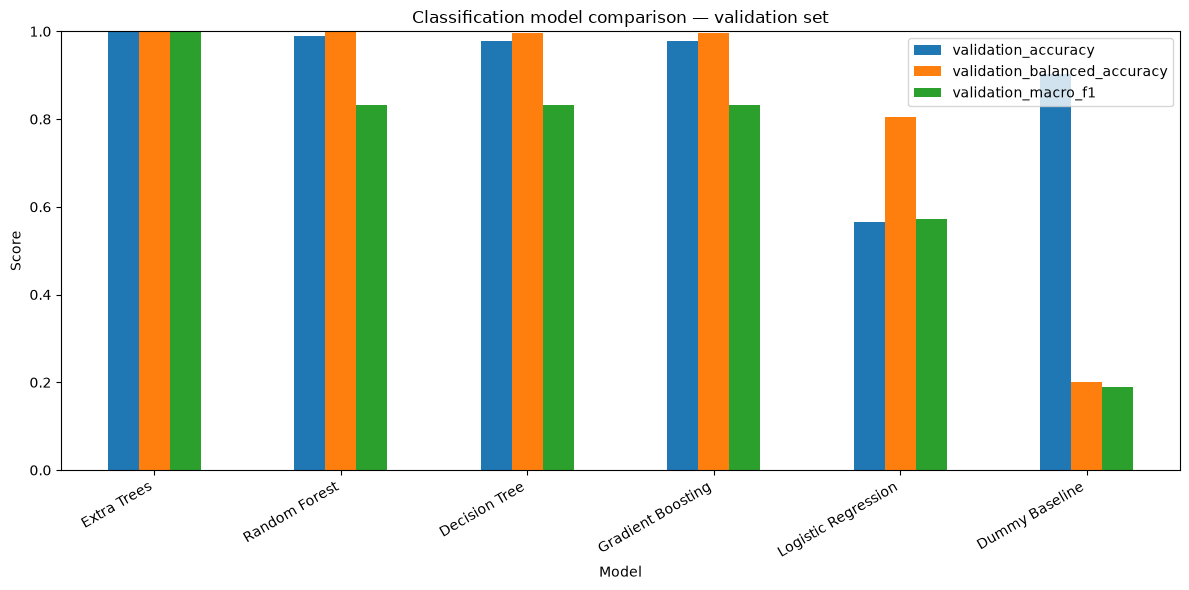

In [8]:
metrics_to_plot = [
    "validation_accuracy",
    "validation_balanced_accuracy",
    "validation_macro_f1"
]

plot_df = comparison.set_index("model")[metrics_to_plot]
ax = plot_df.plot(kind="bar", figsize=(12, 6))
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_title("Classification model comparison — validation set")
ax.set_ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Outcome and conclusion

The chart visualises the same validation comparison. Extra Trees leads all three measures, while Random Forest, Decision Tree and Gradient Boosting also perform strongly.

Logistic Regression performs considerably worse on this dataset, suggesting that a simple linear decision boundary is not sufficient to separate all material groups using these six properties.

The Dummy baseline's high accuracy but low balanced accuracy and macro F1 again demonstrates the effect of class imbalance.

## 9. Select the best model using validation results

In [9]:
best_model_name = comparison.iloc[0]["model"]
best_model = fitted_models[best_model_name]

print("Selected model:", best_model_name)
print("Validation accuracy:",
      round(float(comparison.iloc[0]["validation_accuracy"]), 4))
print("Validation balanced accuracy:",
      round(float(comparison.iloc[0]["validation_balanced_accuracy"]), 4))
print("Validation macro F1:",
      round(float(comparison.iloc[0]["validation_macro_f1"]), 4))

Selected model: Extra Trees
Validation accuracy: 1.0
Validation balanced accuracy: 1.0
Validation macro F1: 1.0


### Outcome and conclusion

**Extra Trees** is selected because it achieved the highest validation macro F1 (1.0000), with balanced accuracy also at 1.0000.

This is a validation-based choice; the test set has not been used to select the model. The next section checks whether the perfect validation result carries over to unseen test records.

## 10. Evaluate the selected model once on the test set

In [10]:
test_predictions = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)
test_balanced_accuracy = balanced_accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(y_test, test_predictions, average="macro", zero_division=0)

print("Selected model:", best_model_name)
print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test balanced accuracy: {test_balanced_accuracy:.3f}")
print(f"Test macro F1: {test_macro_f1:.3f}")

print("\\nTest classification report:")
print(classification_report(y_test, test_predictions, zero_division=0))

Selected model: Extra Trees
Test accuracy: 0.784
Test balanced accuracy: 0.804
Test macro F1: 0.708
\nTest classification report:
                      precision    recall  f1-score   support

A_thermal_insulation       0.65      1.00      0.79        41
           B_masonry       0.00      0.00      0.00         0
          C_concrete       1.00      1.00      1.00         1
   D_timber_biobased       1.00      0.85      0.92        27
            E_boards       0.67      0.57      0.62         7
          F_envelope       1.00      0.56      0.71        45
           G_glazing       1.00      0.85      0.92        13

            accuracy                           0.78       134
           macro avg       0.76      0.69      0.71       134
        weighted avg       0.88      0.78      0.80       134



c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


### Outcome and conclusion — actual test results

Extra Trees achieved the following results on the untouched test split:

- Accuracy: **0.784 (78.4%)**
- Balanced accuracy: **0.804**
- Macro F1: **0.708**

The test result is substantially lower than the perfect validation result. This is an important finding: the validation score alone gave an overly optimistic impression of expected performance.

The test report shows uneven performance by material group:

- Thermal insulation: recall 1.00, but precision 0.65.
- Timber/biobased: F1 0.92.
- Glazing: F1 0.92.
- Envelope: recall 0.56.
- Boards: F1 0.62.
- Concrete: one test record, predicted correctly.
- Masonry: zero actual test records, so its test performance cannot be assessed.

The warning about predicted classes not present in `y_true` occurs because at least one predicted group has no actual examples in this test subset. Masonry has zero support in the test set, so we cannot claim that the classifier works for masonry based on this test.

**Interpretation:** The classifier shows promise, but its test performance is not yet strong or balanced enough to support automatic material classification in production. The split's small class counts also make some per-class results unstable.

## 11. Visualise the test confusion matrix

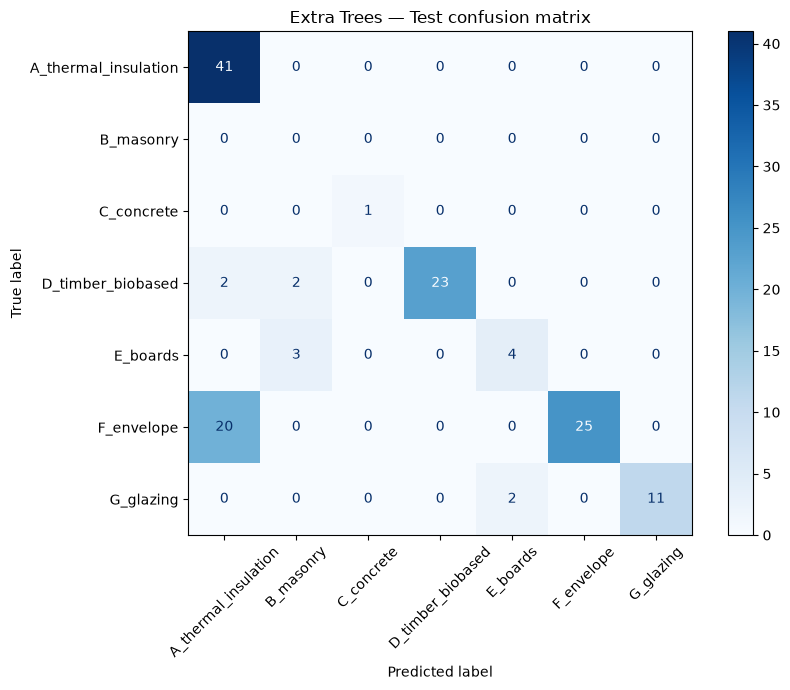

In [11]:
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d",
    ax=ax
)
ax.set_title(f"{best_model_name} — Test confusion matrix")
plt.tight_layout()
plt.show()

### Outcome and conclusion

The confusion matrix shows which groups the selected model predicts correctly and which groups it mixes up. The test results indicate that some categories are easier to identify than others.

In particular, the model has perfect recall for insulation but lower precision, meaning it correctly identifies all actual insulation records in this test set while also assigning some non-insulation records to insulation.

The envelope category has a recall of 0.56, so a substantial share of actual envelope records are missed. These errors matter more than the overall accuracy alone suggests.

## 12. Inspect feature importance where supported

,feature,importance
0,thickness_mm,0.322189
2,thermal_conductivity_W_mK,0.321533
1,thermal_resistance_m2K_W,0.140770
3,compressive_strength_kPa,0.100726
5,tensile_strength_perpendicular_kPa,0.085866
4,vapour_resistance_factor_mu,0.028916


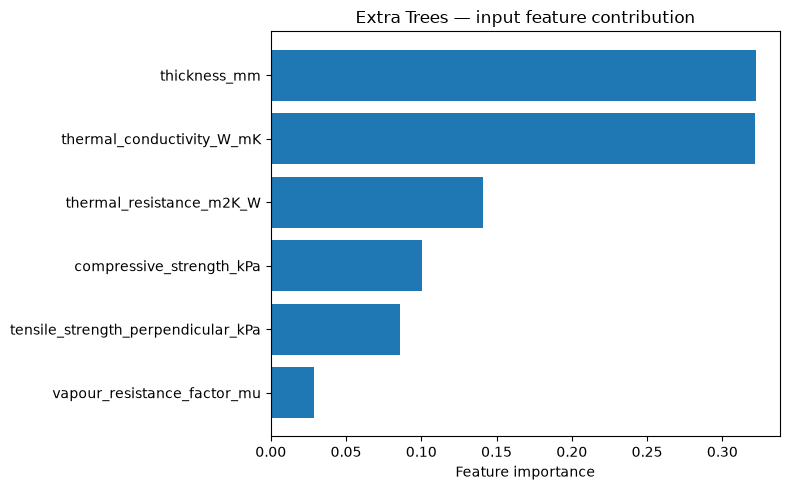

In [12]:
selected_estimator = best_model.named_steps["classifier"]

if hasattr(selected_estimator, "feature_importances_"):
    importance_values = selected_estimator.feature_importances_
    importance_label = "Feature importance"
elif hasattr(selected_estimator, "coef_"):
    importance_values = np.mean(np.abs(selected_estimator.coef_), axis=0)
    importance_label = "Mean absolute coefficient"
else:
    importance_values = None
    importance_label = None

if importance_values is not None:
    importance = pd.DataFrame({
        "feature": usable_features,
        "importance": importance_values
    }).sort_values("importance", ascending=False)

    display(importance)

    plt.figure(figsize=(8, 5))
    plt.barh(importance["feature"][::-1], importance["importance"][::-1])
    plt.xlabel(importance_label)
    plt.title(f"{best_model_name} — input feature contribution")
    plt.tight_layout()
    plt.show()
else:
    importance = pd.DataFrame(columns=["feature", "importance"])
    print("This model does not provide a built-in feature-importance measure.")

### Outcome and conclusion

The Extra Trees feature-importance results are:

| Feature | Importance |
|---|---:|
| Thickness | 0.3222 |
| Thermal conductivity | 0.3215 |
| Thermal resistance | 0.1408 |
| Compressive strength | 0.1007 |
| Tensile strength perpendicular | 0.0859 |
| Vapour resistance factor | 0.0289 |

Thickness and thermal conductivity together account for about 64.4% of the model's total feature importance. Thermal resistance is the third most influential feature.

These values describe how the fitted tree model used the inputs; they do not prove that a feature causes a material to belong to a category. Thermal conductivity and thermal resistance are also related to one another, so their importance should not be interpreted as fully independent contributions.

## 13. Save model comparison, selected model and reports

In [13]:
model_path = MODEL_DIR / "best_material_classifier_v1.joblib"
comparison_path = REPORT_DIR / "material_classification_model_comparison_v1.csv"
predictions_path = REPORT_DIR / "material_classification_test_predictions_v1.csv"
metrics_path = REPORT_DIR / "material_classification_metrics_v1.json"
importance_path = REPORT_DIR / "material_classification_feature_importance_v1.csv"

joblib.dump(best_model, model_path)
comparison.to_csv(comparison_path, index=False)

prediction_output = test_df[metadata_columns].copy()
prediction_output["actual_group"] = y_test.values
prediction_output["predicted_group"] = test_predictions
prediction_output["correct_prediction"] = (
    prediction_output["actual_group"] == prediction_output["predicted_group"]
)
prediction_output.to_csv(predictions_path, index=False)
importance.to_csv(importance_path, index=False)

metrics = {
    "experiment": "Multi-model broad material-group classification",
    "dataset_version": "v1.5.0",
    "target": TARGET,
    "features": usable_features,
    "models_compared": list(models.keys()),
    "selected_model": best_model_name,
    "selection_rule": "Highest validation macro F1; balanced accuracy used as tie-breaker",
    "training_records": int(len(X_train)),
    "validation_records": int(len(X_val)),
    "test_records": int(len(X_test)),
    "validation_comparison": comparison.to_dict(orient="records"),
    "test": {
        "accuracy": float(test_accuracy),
        "balanced_accuracy": float(test_balanced_accuracy),
        "macro_f1": float(test_macro_f1)
    },
    "warning": "Predictions are exploratory and must not replace verified product documentation."
}
metrics_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")

print("Saved selected model:", model_path)
print("Saved model comparison:", comparison_path)
print("Saved test predictions:", predictions_path)
print("Saved metrics:", metrics_path)
print("Saved feature importance:", importance_path)

Saved selected model: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\03_Models\material_classification\best_material_classifier_v1.joblib
Saved model comparison: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\material_classification_model_comparison_v1.csv
Saved test predictions: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\material_classification_test_predictions_v1.csv
Saved metrics: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\material_classification_metrics_v1.json
Saved feature importance: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performanc

### Outcome and conclusion

The notebook saved the selected Extra Trees model, the validation comparison, test predictions, test metrics and feature-importance table.

These files provide a reproducible record of the experiment. The selected model is an experimental artefact only; it should not yet be connected to Revit as an automatic decision-maker.

# Final conclusion — Material Classification

This experiment compared six classifiers using six numerical product properties and the dataset's existing train/validation/test split.

## What we did

The target was the broad `material_category_group`, containing seven groups. The dataset is heavily imbalanced: 1,674 of 1,941 records belong to thermal insulation, while concrete and masonry have only 11 and 24 records respectively.

The six selected inputs were thickness, thermal resistance, thermal conductivity, compressive strength, vapour resistance factor and tensile strength perpendicular. Missing values were handled using median imputation fitted within each model pipeline, using training data only.

We compared Dummy Baseline, Logistic Regression, Decision Tree, Random Forest, Extra Trees and Gradient Boosting.

## What the results tell us

Extra Trees achieved the best validation result:
- Validation accuracy: 1.000
- Validation balanced accuracy: 1.000
- Validation macro F1: 1.000

However, its untouched test results were lower:
- Test accuracy: **0.784**
- Test balanced accuracy: **0.804**
- Test macro F1: **0.708**

This difference is important. The perfect validation result did not carry over to the test set. The test report shows good results for timber/biobased and glazing, but weaker performance for boards and envelope. Masonry has no actual test examples, so this experiment cannot establish how well the model classifies masonry.

The feature-importance analysis shows that thickness and thermal conductivity were the two strongest inputs, followed by thermal resistance. These are associations learned by the model, not proof of physical causation.

## Limitations

1. The dataset is strongly imbalanced, with insulation dominating the records.
2. Some material groups have very few examples, making their evaluation uncertain.
3. The validation result is perfect but the test result is materially lower; further investigation is needed.
4. Some test classes have very small support, and masonry has zero actual test records.
5. The model predicts broad dataset categories; it does not verify manufacturer claims, product identity, certification or regulatory compliance.

## Final recommendation for SpecSynth AI

Keep Extra Trees as the **current experimental candidate**, not as a production-approved classifier. Before integration, investigate the validation/test performance gap, review the group-level split composition, and obtain more representative examples for underrepresented categories. Consider reporting prediction confidence and allowing the system to return “insufficient evidence” rather than forcing a category when confidence is low.

**Final takeaway:** We successfully compared six algorithms and identified Extra Trees as the strongest validation candidate. Its test macro F1 of 0.708 shows useful but imperfect classification performance. The experiment is complete, but the model is not yet ready to make automatic product-classification or compliance decisions.